# code_104 · Reverse derivatives and gradient checks

**Book:** section 21.2. A self-contained neural-training laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_21_GUIDE.md), [run evidence](../CHAPTER_21_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_104).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2204;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2204


<a id="graph"></a>
 ## A complete tiny deflection computation
 Use a two-input, two-tanh-unit, one-output network with nine explicit parameters and one generated teaching target. Trace its forward values and reverse derivatives. Compare manual parameter derivatives, PyTorch reverse-mode autodiff and central finite differences. Double and single precision use the same mathematical expression. This local derivative check tests code, not the physical validity of a deflection law. No field observations or fitted assessment labels enter the fixture.


,parameter,autodiff,manual
0,0,0.313902,0.313902
1,1,-0.538117,-0.538117
2,2,-0.243507,-0.243507
3,3,0.417441,0.417441
4,4,-0.448431,-0.448431
5,5,0.347867,0.347867
6,6,0.304002,0.304002
7,7,-0.281193,-0.281193
8,8,-0.693752,-0.693752


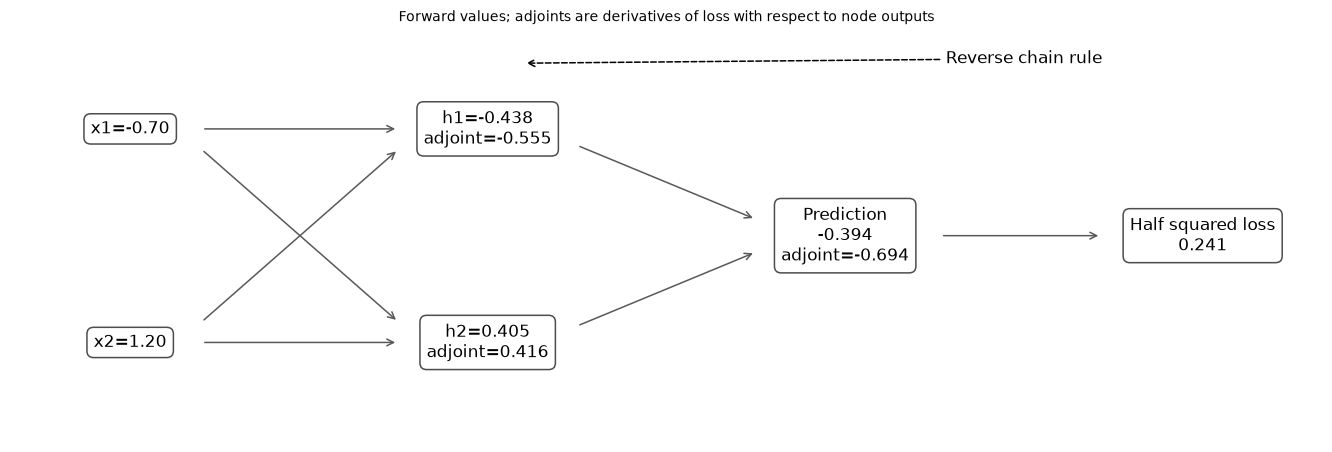

In [2]:
inputs=torch.tensor([-.7,1.2]);target=torch.tensor(.3);initial=torch.tensor([.4,-.2,.1,.5,.05,-.1,.8,-.6,.2]);theta=initial.clone().requires_grad_()
def forward(parameters):
    z=parameters[:4].reshape(2,2)@inputs.to(parameters.dtype)+parameters[4:6];h=torch.tanh(z);prediction=parameters[6:8]@h+parameters[8]
    return prediction,z,h
def objective(parameters):return .5*(forward(parameters)[0]-target.to(parameters.dtype))**2
prediction,z,h=forward(theta);loss=objective(theta);automatic=torch.autograd.grad(loss,theta)[0]
delta_out=prediction.detach()-target;delta_hidden=delta_out*theta[6:8].detach()*(1-h.detach()**2)
manual=torch.cat([torch.outer(delta_hidden,inputs).flatten(),delta_hidden,delta_out*h.detach(),delta_out.reshape(1)])
torch.testing.assert_close(automatic,manual,atol=1e-12,rtol=1e-12)
assert torch.autograd.gradcheck(objective,(theta,),eps=1e-6,atol=1e-5,rtol=1e-3)
rows=[]
for dtype in [torch.float64,torch.float32]:
    base=initial.to(dtype).clone().requires_grad_();reference=torch.autograd.grad(objective(base),base)[0].detach().numpy().astype(float)
    for epsilon in [1e-1,1e-2,1e-3,1e-4,1e-5,1e-6,1e-7,1e-8]:
        numerical=[]
        for j in range(len(initial)):
            positive=initial.to(dtype).clone();negative=positive.clone();positive[j]+=epsilon;negative[j]-=epsilon
            numerical.append(float((objective(positive)-objective(negative)).detach()/(2*epsilon)))
        error=float(np.linalg.norm(np.array(numerical)-reference)/np.linalg.norm(reference));rows.append({'dtype':str(dtype),'epsilon':epsilon,'relative_gradient_error':error})
theta.grad=None;objective(theta).backward();first=theta.grad.clone();objective(theta).backward();torch.testing.assert_close(theta.grad,2*first);theta.grad=None
updated=initial-.1*automatic;after=float(objective(updated));assert after<float(loss.detach())
detached_failure=False
try:objective(theta.detach()).backward()
except RuntimeError:detached_failure=True
assert detached_failure
RESULTS.update(prediction=float(prediction.detach()),hidden_values=h.detach().tolist(),preactivations=z.detach().tolist(),loss_before=float(loss.detach()),loss_after_update=after,automatic_gradient=automatic.tolist(),manual_gradient=manual.tolist(),finite_difference=rows,gradcheck_passed=True,detached_graph_rejected=detached_failure,gradient_accumulation_factor=2)
display(pd.DataFrame({'parameter':range(9),'autodiff':automatic.numpy(),'manual':manual.numpy()}))
fig,ax=plt.subplots(figsize=(12,4));ax.set(xlim=(-1,10),ylim=(-1,4));ax.axis('off')
nodes=[((0,2.8),f'x1={float(inputs[0]):.2f}'),((0,.2),f'x2={float(inputs[1]):.2f}'),((3,2.8),f'h1={float(h[0].detach()):.3f}\nadjoint={float(delta_hidden[0]/(1-h[0].detach()**2)):.3f}'),((3,.2),f'h2={float(h[1].detach()):.3f}\nadjoint={float(delta_hidden[1]/(1-h[1].detach()**2)):.3f}'),((6,1.5),f'Prediction\n{float(prediction.detach()):.3f}\nadjoint={float(delta_out):.3f}'),((9,1.5),f'Half squared loss\n{float(loss.detach()):.3f}')]
for (a,b),label in nodes:ax.text(a,b,label,ha='center',va='center',bbox={'facecolor':'white','edgecolor':'.3','boxstyle':'round,pad=.4'})
for start,end in [((.6,2.8),(2.25,2.8)),((.6,.2),(2.25,.2)),((.6,2.55),(2.25,.45)),((.6,.45),(2.25,2.55)),((3.75,2.6),(5.25,1.7)),((3.75,.4),(5.25,1.3)),((6.8,1.5),(8.15,1.5))]:ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'.35'})
ax.annotate('Reverse chain rule',xy=(3.3,3.6),xytext=(7.5,3.6),ha='center',arrowprops={'arrowstyle':'->','linestyle':'--','color':'black'});ax.set_title('Forward values; adjoints are derivatives of loss with respect to node outputs');plt.show()


<a id="checks"></a>
 ## A derivative is local evidence
 Reverse mode reuses stored intermediate values and accumulates all paths into a parameter. Central differences instead perturb parameters and subtract nearby losses; truncation error competes with floating-point cancellation. A smaller step is not always a better check. Autodiff differentiates executed operations rather than deriving a symbolic closed form. Existing .grad buffers accumulate unless cleared. Detaching a needed graph removes its derivative path; the expected rejected backward call is caught explicitly. One small successful update does not certify convergence or generalization.


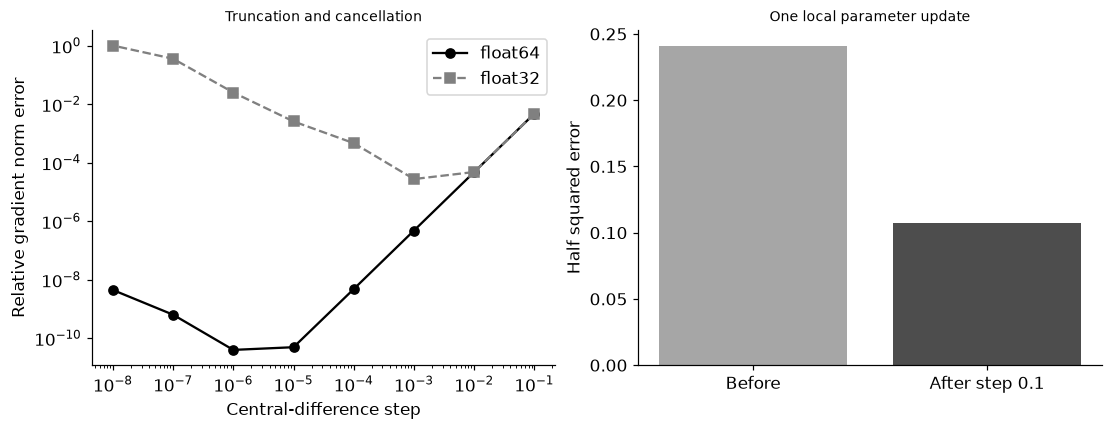

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
for dtype,style,color in [('torch.float64','o-','black'),('torch.float32','s--','.5')]:
    subset=[r for r in rows if r['dtype']==dtype];axes[0].loglog([r['epsilon'] for r in subset],[max(r['relative_gradient_error'],1e-16) for r in subset],style,color=color,label=dtype.replace('torch.',''))
axes[0].set(xlabel='Central-difference step',ylabel='Relative gradient norm error',title='Truncation and cancellation');axes[0].legend()
axes[1].bar([0,1],[float(loss.detach()),after],color=['.65','.3']);axes[1].set(xticks=[0,1],xticklabels=['Before','After step 0.1'],ylabel='Half squared error',title='One local parameter update');plt.show()
assert np.isfinite([r['relative_gradient_error'] for r in rows]).all()


In [4]:
summary={'example_id':'code_104','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['explicit computational graph', 'manual reverse-mode derivatives', 'finite differences and gradcheck', 'gradient accumulation and updates'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["explicit computational graph", "manual reverse-mode derivatives", "finite differences and gradcheck", "gradient accumulation and updates"], "elapsed_seconds": 0.966, "example_id": "code_104", "hardware": "Darwin arm64 CPU", "results": {"automatic_gradient": [0.31390177075707465, -0.5381173212978423, -0.24350713749032066, 0.417440807126264, -0.4484311010815352, 0.3478673392718867, 0.3040017549521085, -0.28119256463946446, -0.693752237079892], "detached_graph_rejected": true, "finite_difference": [{"dtype": "torch.float64", "epsilon": 0.1, "relative_gradient_error": 0.00469150167751583}, {"dtype": "torch.float64", "epsilon": 0.01, "relative_gradient_error": 4.7168826964138646e-05}, {"dtype": "torch.float64", "epsilon": 0.001, "relative_gradient_error": 4.7171371206802574e-07}, {"dtype": "torch.float64", "epsilon": 0.0001, "relative_gradient_error": 4.717193882732605e-09}, {"dtype": "torch.float64", "epsilon": 1e-05, "relative_gradient_er